# RetenIA | Customer Churn: del dato a la propuesta comercial

**Aprendizaje Automático - Solución individual.** Se conserva y amplía el avance original (auditoría y pipeline). El dataset fuente es Telco Customer Churn. Se trabaja con `Churn=Yes` como clase positiva.

## Reglas metodológicas
- Mantenga **test aislado** hasta la evaluación final.
- Use `ColumnTransformer` y `Pipeline`.
- Compare al menos dos modelos con el mismo protocolo.
- No seleccione un modelo solo por Accuracy.
- La importancia predictiva de una variable **no demuestra causalidad**.
- La propuesta de negocio debe estar respaldada por sus resultados.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (classification_report, roc_auc_score,
                             ConfusionMatrixDisplay, precision_score,
                             recall_score, f1_score)

RANDOM_STATE = 42


## 1. Auditoría y preparación

Cargue `WA_Fn-UseC_-Telco-Customer-Churn.csv` y analice dimensiones, tipos, faltantes/inconsistencias, distribución de `Churn` y el problema de `TotalCharges`.

**TODO:** escriba 3–5 hallazgos que afecten decisiones posteriores.


In [2]:
# TODO 1 — Cargar y auditar el dataset.
# TODO 2 — Corregir TotalCharges de manera justificada.

from pathlib import Path
import zipfile

CSV_NAME = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
ZIP_NAME = "TelcoDataset.zip"

# Carga flexible: usa el CSV si está extraído; si no, lo lee directamente del ZIP.
if Path(CSV_NAME).exists():
    df = pd.read_csv(CSV_NAME)
elif Path(ZIP_NAME).exists():
    with zipfile.ZipFile(ZIP_NAME) as z:
        with z.open(CSV_NAME) as f:
            df = pd.read_csv(f)
else:
    raise FileNotFoundError(
        f"No se encontró {CSV_NAME} ni {ZIP_NAME} en el directorio de trabajo."
    )

print(f"Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas")
print(f"Filas duplicadas exactas: {df.duplicated().sum()}")
print(f"customerID únicos: {df['customerID'].nunique()} de {len(df)}")

print("\nTipos de datos:")
display(df.dtypes.to_frame("dtype"))

print("\nValores faltantes detectados directamente por pandas:")
display(df.isna().sum().to_frame("n_missing").query("n_missing > 0"))

print("\nDistribución de Churn:")
churn_dist = pd.DataFrame({
    "n": df["Churn"].value_counts(),
    "porcentaje": (df["Churn"].value_counts(normalize=True) * 100).round(2)
})
display(churn_dist)

# TotalCharges aparece como object porque contiene cadenas en blanco.
blank_totalcharges = df["TotalCharges"].astype(str).str.strip().eq("")
print(f"Registros con TotalCharges en blanco: {blank_totalcharges.sum()}")
if blank_totalcharges.any():
    display(df.loc[blank_totalcharges, [
        "customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"
    ]])

# Corrección de tipo: los blancos se convierten en NaN.
# No se imputa aquí para evitar calcular estadísticas con todo el dataset;
# la imputación se realizará dentro del Pipeline usando únicamente train.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("\nDespués de la conversión de TotalCharges:")
print("dtype:", df["TotalCharges"].dtype)
print("NaN:", df["TotalCharges"].isna().sum())
print("Todos los NaN de TotalCharges tienen tenure=0:",
      bool((df.loc[df["TotalCharges"].isna(), "tenure"] == 0).all()))

display(df.head())


Dimensiones: 7043 filas x 21 columnas
Filas duplicadas exactas: 0
customerID únicos: 7043 de 7043

Tipos de datos:


,dtype
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object



Valores faltantes detectados directamente por pandas:


,n_missing



Distribución de Churn:


,n,porcentaje
Churn,,
No,5174,73.46
Yes,1869,26.54


Registros con TotalCharges en blanco: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No



Después de la conversión de TotalCharges:
dtype: float64
NaN: 11
Todos los NaN de TotalCharges tienen tenure=0: True


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Hallazgos de la auditoría (punto 1)

1. El dataset contiene **7043 clientes y 21 columnas**, sin filas duplicadas exactas. `customerID` es único en las 7043 observaciones, por lo que funciona como identificador y no como una característica con capacidad de generalización.
2. La variable objetivo está **desbalanceada**: aproximadamente **73.46%** de los clientes no abandonan (`No`) y **26.54%** sí abandonan (`Yes`). Esto justifica un split estratificado y, en etapas posteriores, no basarse únicamente en Accuracy.
3. `TotalCharges` se importa como `object` porque existen **11 cadenas en blanco**. Los 11 casos corresponden a clientes con `tenure = 0`. Se convierte la columna a formato numérico con `errors="coerce"`, dejando esos casos como `NaN`; la imputación se hará dentro del pipeline para que el valor de reemplazo se aprenda solo con train.
4. Existen variables numéricas y muchas variables categóricas, por lo que se requiere un preprocesamiento distinto para ambos tipos: escalado/imputación para numéricas y One-Hot Encoding para categóricas.
5. No se detectaron valores faltantes estándar antes de corregir `TotalCharges`; el problema estaba oculto como texto en blanco. Por eso la auditoría no debe limitarse a `isna()`.


## 2. Train/Test y pipeline
Separe objetivo/predictores. Analice `customerID`. Realice un split estratificado.

Construya un `ColumnTransformer` con tratamiento numérico y categórico y encapsúlelo en un `Pipeline`.

**Explique:** ¿cómo evita su procedimiento el data leakage?


In [3]:
# TODO 3 — X, y y split.
# TODO 4 — Columnas numéricas/categóricas.
# TODO 5 — Preprocesamiento.
# TODO 6 — Pipeline completo.

# customerID es un identificador único, no una característica generalizable.
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"].map({"No": 0, "Yes": 1})

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Proporción Churn=1 total:", round(y.mean(), 4))
print("Proporción Churn=1 train:", round(y_train.mean(), 4))
print("Proporción Churn=1 test:", round(y_test.mean(), 4))

# SeniorCitizen es un indicador 0/1 y se trata como categórico.
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in X_train.columns if c not in num_cols]

print("\nColumnas numéricas:", num_cols)
print("\nColumnas categóricas:", cat_cols)

# Pipeline numérico: imputación con la mediana aprendida SOLO en train + escalado.
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Pipeline categórico: imputación robusta + One-Hot Encoding.
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, num_cols),
        ("cat", categorical_transformer, cat_cols)
    ]
)

# Pipeline de clasificación listo para usarse más adelante.
# En los puntos 1 y 2 únicamente se define; NO se entrena ni se evalúa todavía.
pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

print("\nPipeline construido correctamente:")
print(pipeline)


Train: (5634, 19) | Test: (1409, 19)
Proporción Churn=1 total: 0.2654
Proporción Churn=1 train: 0.2654
Proporción Churn=1 test: 0.2654

Columnas numéricas: ['tenure', 'MonthlyCharges', 'TotalCharges']

Columnas categóricas: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Pipeline construido correctamente:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                

### ¿Cómo se evita el *data leakage*? (punto 2)

El conjunto se divide en **train y test antes de aprender cualquier parámetro de preprocesamiento**, usando `stratify=y` para conservar aproximadamente la misma proporción de churn en ambos conjuntos. `TotalCharges` solo se convierte de texto a número antes del split; esa operación es determinista y no aprende información estadística del dataset.

La imputación de valores faltantes, el escalado y el One-Hot Encoding están dentro de un `Pipeline`/`ColumnTransformer`. Por tanto, cuando posteriormente se llame a `fit` (o se use validación cruzada), la mediana, las categorías y los parámetros de escalado se aprenderán **únicamente con los datos de entrenamiento de cada ajuste o fold**. El conjunto de test permanece aislado hasta la evaluación final. Además, `Churn` se elimina de `X` y `customerID` no se usa como predictor.


Las secciones siguientes continúan el avance, respetando el aislamiento de test.

## 3. Modelos base con validación cruzada

Comparamos regresión logística y Random Forest con exactamente las mismas particiones estratificadas de entrenamiento. Se reportan Accuracy, Precision, Recall, F1 y ROC-AUC. **F1 de la clase abandono** es el criterio de selección inicial, porque se necesitan precisión y cobertura equilibradas.

In [4]:
from IPython.display import display
from sklearn.model_selection import cross_val_score, RandomizedSearchCV
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve
from sklearn.base import clone
from scipy.stats import loguniform
import optuna, joblib, time, json, warnings
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from explain_utils import lime_for_encoded

A = Path('artifacts'); A.mkdir(exist_ok=True)
CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
SCORING = {'accuracy': 'accuracy', 'precision': 'precision', 'recall': 'recall', 'f1': 'f1', 'roc_auc': 'roc_auc'}

def make_lr(C=1.0, class_weight=None, fit_intercept=True):
    return Pipeline([('preprocessor', clone(preprocessor)),
                     ('model', LogisticRegression(C=C, class_weight=class_weight,
                                                 fit_intercept=fit_intercept,
                                                 solver='liblinear', max_iter=1200,
                                                 random_state=RANDOM_STATE))])

candidates = {
    'Regresion logistica': make_lr(),
    'Random Forest': Pipeline([('preprocessor', clone(preprocessor)),
                               ('model', RandomForestClassifier(n_estimators=120,
                                  min_samples_leaf=2, n_jobs=1, random_state=RANDOM_STATE))])
}
cv_model_rows = []
for name, candidate in candidates.items():
    t0 = time.perf_counter()
    r = cross_validate(candidate, X_train, y_train, cv=CV, scoring=SCORING, n_jobs=1)
    cv_model_rows.append({'modelo': name, 'tiempo_cv_s': round(time.perf_counter()-t0,2),
                         **{'cv_'+k: round(float(np.mean(r['test_'+k])),4) for k in SCORING}})
cv_model_table = pd.DataFrame(cv_model_rows).sort_values('cv_f1', ascending=False)
display(cv_model_table)
cv_model_table.to_csv(A/'model_comparison.csv', index=False)
print('Criterio principal predefinido para la selección: F1 de abandono en CV; ROC-AUC y recall complementan.')



/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,modelo,tiempo_cv_s,cv_accuracy,cv_precision,cv_recall,cv_f1,cv_roc_auc
0,Regresion logistica,0.19,0.8032,0.6557,0.5445,0.5949,0.8458
1,Random Forest,1.59,0.7961,0.6561,0.4876,0.5592,0.8349


Criterio principal predefinido para la selección: F1 de abandono en CV; ROC-AUC y recall complementan.


## 4. Grid Search, Random Search y TPE bayesiano

Todas las búsquedas usan regresión logística, el mismo pipeline y los mismos tres folds; el presupuesto es de 24 configuraciones por método. C se explora en [0.03, 10]; `class_weight` en {None, balanced}, `fit_intercept` en {True, False}. Grid recorre 24 combinaciones; Random muestrea al azar; TPE aprende de los mejores ensayos. El tiempo medido es propio de esta máquina, no una velocidad universal.

Espacio: C entre 0.03 y 10; class_weight en {None, balanced}; fit_intercept en {True, False}.
Grid = 6 x 2 x 2 = 24; Random = 24; TPE = 24; CV estratificada = 3 folds.


,estrategia,cv_f1,tiempo_s,configuraciones,folds,parametros
2,Bayesiano TPE,0.6298,3.42,24,3,"{'C': 1.3047177725867953, 'class_weight': 'bal..."
0,Grid Search,0.6292,3.59,24,3,"{'C': 0.1, 'class_weight': 'balanced', 'fit_in..."
1,Random Search,0.6291,3.34,24,3,"{'C': np.float64(0.13489373196232501), 'class_..."


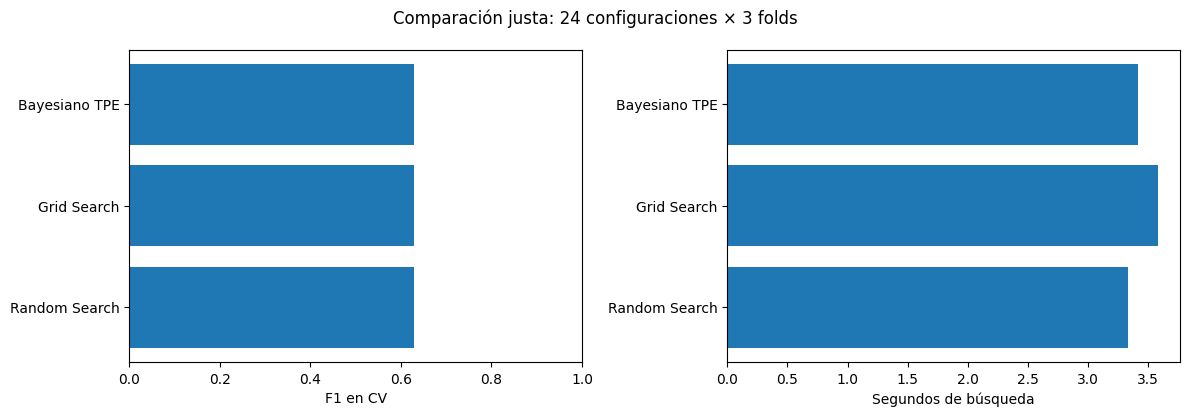

Estrategia seleccionada exclusivamente por validación cruzada: Bayesiano TPE {'C': 1.3047177725867953, 'class_weight': 'balanced', 'fit_intercept': False}


In [5]:
# Grid, Random y TPE: mismo pipeline, mismos 3 folds, 24 configuraciones por estrategia.
PARAM_GRID = {
  'model__C': [0.03, 0.1, 0.3, 1.0, 3.0, 10.0],
  'model__class_weight': [None, 'balanced'],
  'model__fit_intercept': [True, False]
}
PARAM_RANDOM = {
  'model__C': loguniform(0.03, 10),
  'model__class_weight': [None, 'balanced'],
  'model__fit_intercept': [True, False]
}
print('Espacio: C entre 0.03 y 10; class_weight en {None, balanced}; fit_intercept en {True, False}.')
print('Grid = 6 x 2 x 2 = 24; Random = 24; TPE = 24; CV estratificada = 3 folds.')
base = make_lr()
grid = GridSearchCV(base, PARAM_GRID, scoring='f1', cv=CV, n_jobs=1, refit=True)
t0=time.perf_counter(); grid.fit(X_train,y_train); sec_grid=time.perf_counter()-t0
random = RandomizedSearchCV(base, PARAM_RANDOM, n_iter=24, scoring='f1', cv=CV,
                            random_state=RANDOM_STATE, n_jobs=1, refit=True)
t0=time.perf_counter(); random.fit(X_train,y_train); sec_random=time.perf_counter()-t0
optuna.logging.set_verbosity(optuna.logging.WARNING)

def tpe_obj(trial):
    model = make_lr(
        C=trial.suggest_float('C',0.03,10,log=True),
        class_weight=trial.suggest_categorical('class_weight',[None,'balanced']),
        fit_intercept=trial.suggest_categorical('fit_intercept',[True,False]))
    return float(cross_val_score(model,X_train,y_train,cv=CV,scoring='f1',n_jobs=1).mean())

tpe_study = optuna.create_study(direction='maximize',sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
t0=time.perf_counter(); tpe_study.optimize(tpe_obj,n_trials=24,show_progress_bar=False); sec_tpe=time.perf_counter()-t0

def normalize_params(params):
    return {k.replace('model__',''):v for k,v in params.items()}

search_runs = [
  ('Grid Search',grid.best_score_,sec_grid,24,normalize_params(grid.best_params_)),
  ('Random Search',random.best_score_,sec_random,24,normalize_params(random.best_params_)),
  ('Bayesiano TPE',tpe_study.best_value,sec_tpe,24,tpe_study.best_params)
]
search_table=pd.DataFrame([{'estrategia':name,'cv_f1':round(float(score),4),
                           'tiempo_s':round(float(secs),2),'configuraciones':int(n),
                           'folds':3,'parametros':str(pars)}
    for name,score,secs,n,pars in search_runs]).sort_values(['cv_f1','tiempo_s'],ascending=[False,True])
display(search_table)
search_table.to_csv(A/'search_comparison.csv',index=False)
fig,axs=plt.subplots(1,2,figsize=(12,4.2))
axs[0].barh(search_table['estrategia'],search_table['cv_f1']);axs[0].set_xlabel('F1 en CV');axs[0].set_xlim(0,1);axs[0].invert_yaxis()
axs[1].barh(search_table['estrategia'],search_table['tiempo_s']);axs[1].set_xlabel('Segundos de búsqueda');axs[1].invert_yaxis()
fig.suptitle('Comparación justa: 24 configuraciones × 3 folds');fig.tight_layout();fig.savefig(A/'optimizers.png',dpi=155,bbox_inches='tight');plt.show()
winner=search_table.iloc[0]['estrategia']
win_params=next(pars for name,score,secs,n,pars in search_runs if name==winner)
print('Estrategia seleccionada exclusivamente por validación cruzada:',winner,win_params)



## 5. Optimización multiobjetivo mediante NSGA-II

Definimos dos objetivos sobre validación cruzada: **maximizar** $f_1=\frac{1}{K}\sum_{k=1}^K F1_k$ y **minimizar** $f_2=\frac{1}{K}\sum_{k=1}^K \frac{\#\{\hat p_{ik}\geq\tau\}}{n_k}$. El segundo representa la proporción de clientes que el equipo debería contactar. El frente de Pareto reúne soluciones no dominadas; seleccionamos la de mayor F1 con tasa de contacto <=30% (si existe). El test sigue cerrado.

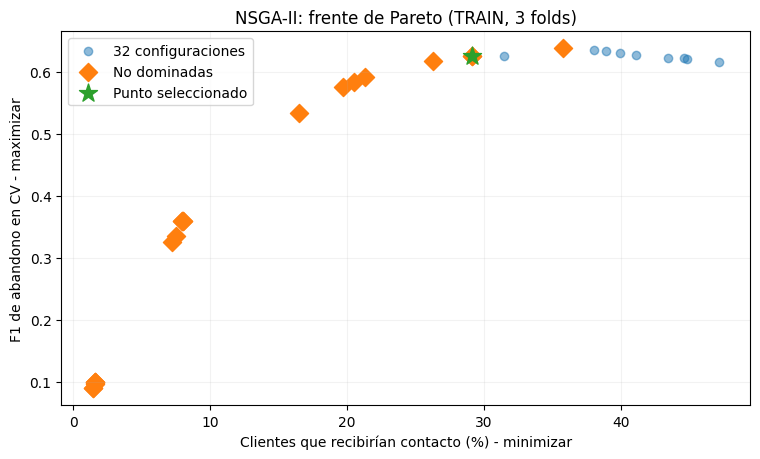

Soluciones no dominadas: 21 Tiempo: 3.94 segundos


,trial,cv_f1,contact_rate,C,class_weight,fit_intercept,threshold
0,1,0.0898,0.0142,0.0420,None,True,0.7819
16,25,0.0898,0.0142,0.0420,None,False,0.7819
13,22,0.0971,0.0156,2.7082,None,True,0.7819
17,26,0.0982,0.0158,1.1211,None,True,0.7819
15,24,0.0994,0.0162,0.4244,None,False,0.7819
20,31,0.0994,0.0162,0.4244,None,True,0.7818
3,8,0.0994,0.0162,0.4244,None,True,0.7818
12,21,0.3252,0.0721,0.0310,None,True,0.6850
10,19,0.3349,0.0749,0.0420,None,True,0.6850
4,9,0.3593,0.0797,2.7082,None,False,0.6850


Solución elegida (máximo F1 con contacto <= 30%, si existe): {'trial': 11, 'cv_f1': 0.6262407141580294, 'contact_rate': 0.2912673056443025, 'C': 0.04203965712872512, 'class_weight': None, 'fit_intercept': True, 'threshold': 0.39519819845795867}


In [6]:
# Frente multiobjetivo: F1 alto y tasa de contactos baja (capacidad del equipo de retención).
# Objetivos: max E_k[F1(y_val,p_val>=tau)] y min E_k[mean(p_val>=tau)] en 3 folds de TRAIN.
def multi_obj(trial):
    c=trial.suggest_float('C',0.03,10,log=True)
    w=trial.suggest_categorical('class_weight',[None,'balanced'])
    inter=trial.suggest_categorical('fit_intercept',[True,False])
    threshold=trial.suggest_float('threshold',0.20,0.80)
    fold_f1=[]; fold_contacts=[]
    for train_idx, valid_idx in CV.split(X_train,y_train):
        fitmodel=make_lr(C=c,class_weight=w,fit_intercept=inter)
        fitmodel.fit(X_train.iloc[train_idx],y_train.iloc[train_idx])
        prob=fitmodel.predict_proba(X_train.iloc[valid_idx])[:,1]
        pred=(prob>=threshold).astype(int)
        fold_f1.append(f1_score(y_train.iloc[valid_idx],pred,zero_division=0))
        fold_contacts.append(float(pred.mean()))
    return float(np.mean(fold_f1)),float(np.mean(fold_contacts))

mo_study=optuna.create_study(directions=['maximize','minimize'],
             sampler=optuna.samplers.NSGAIISampler(seed=RANDOM_STATE,population_size=8))
t0=time.perf_counter();mo_study.optimize(multi_obj,n_trials=32,show_progress_bar=False);sec_pareto=time.perf_counter()-t0
all_trials=pd.DataFrame([{'trial':t.number,'cv_f1':t.values[0],
             'contact_rate':t.values[1],**t.params} for t in mo_study.trials if t.values is not None])
front=pd.DataFrame([{'trial':t.number,'cv_f1':t.values[0],
             'contact_rate':t.values[1],**t.params} for t in mo_study.best_trials])
# Business constraint predefined: prioritize the greatest CV F1 among front members contacting at most 30%.
feasible=front[front['contact_rate']<=0.30]
chosen_pareto=(feasible if not feasible.empty else front).sort_values(
    ['cv_f1','contact_rate'],ascending=[False,True]).iloc[0]
all_trials.to_csv(A/'all_nsga2_trials.csv',index=False)
front.to_csv(A/'pareto_front.csv',index=False)
fig,ax=plt.subplots(figsize=(7.7,4.7))
ax.scatter(100*all_trials.contact_rate,all_trials.cv_f1,alpha=.50,label='32 configuraciones')
ax.scatter(100*front.contact_rate,front.cv_f1,s=85,marker='D',label='No dominadas')
ax.scatter([100*chosen_pareto.contact_rate],[chosen_pareto.cv_f1],s=185,marker='*',label='Punto seleccionado')
ax.set_xlabel('Clientes que recibirían contacto (%) - minimizar')
ax.set_ylabel('F1 de abandono en CV - maximizar')
ax.set_title('NSGA-II: frente de Pareto (TRAIN, 3 folds)');ax.legend();ax.grid(alpha=.16)
fig.tight_layout();fig.savefig(A/'pareto.png',dpi=155,bbox_inches='tight');plt.show()
print('Soluciones no dominadas:',len(front),'Tiempo:',round(sec_pareto,2),'segundos')
display(front.sort_values('contact_rate').round(4))
print('Solución elegida (máximo F1 con contacto <= 30%, si existe):',chosen_pareto.to_dict())



## 6. Evaluación final, matriz de confusión y ranking

Solo después de elegir modelo/hiperparámetros por CV, evaluamos una sola vez en test (umbral 0.50). Construimos un ranking de riesgo y priorizamos el 10% superior. El ranking es predictivo, no demuestra que una oferta cause retención.

EVALUACIÓN FINAL HOLDOUT (TEST, N= 1409 ):


,accuracy,precision,recall,f1,roc_auc,prob_threshold
0,0.7388,0.5052,0.7834,0.6143,0.8414,0.5


              precision    recall  f1-score   support

    Se queda       0.90      0.72      0.80      1035
    Abandona       0.51      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



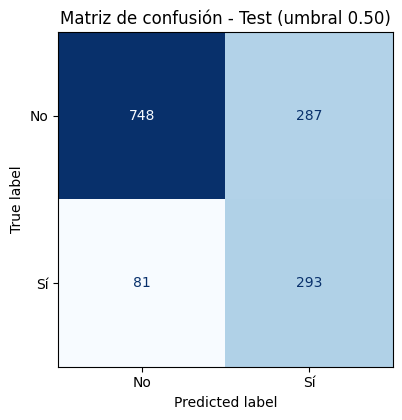

Top 10% de riesgo:

 141 clientes de 1409 | churn observado en subgrupo: 0.752 | tasa general holdout: 0.265


['artifacts/model.joblib']

In [7]:
# SOLO AHORA, una vez finalizada la selección por CV, se toca TEST.
final_model=make_lr(C=float(win_params['C']),class_weight=win_params['class_weight'],
                    fit_intercept=bool(win_params['fit_intercept']))
final_model.fit(X_train,y_train)
p_test=final_model.predict_proba(X_test)[:,1]
pred_test=(p_test>=0.5).astype(int)
test_metrics={
 'accuracy':float(accuracy_score(y_test,pred_test)),
 'precision':float(precision_score(y_test,pred_test,zero_division=0)),
 'recall':float(recall_score(y_test,pred_test,zero_division=0)),
 'f1':float(f1_score(y_test,pred_test,zero_division=0)),
 'roc_auc':float(roc_auc_score(y_test,p_test)),
 'confusion_matrix':confusion_matrix(y_test,pred_test).tolist(),
 'n_test':int(len(y_test)), 'model':'Regresión logística',
 'winning_strategy':winner,'prob_threshold':0.5
}
print('EVALUACIÓN FINAL HOLDOUT (TEST, N=',len(y_test),'):')
display(pd.DataFrame([{k:round(v,4) for k,v in test_metrics.items() if isinstance(v,float)}]))
print(classification_report(y_test,pred_test,target_names=['Se queda','Abandona'],zero_division=0))
fig,ax=plt.subplots(figsize=(5.7,4.3)); ConfusionMatrixDisplay.from_predictions(
    y_test,pred_test,display_labels=['No','Sí'],cmap='Blues',ax=ax,colorbar=False)
ax.set_title('Matriz de confusión - Test (umbral 0.50)')
fig.tight_layout();fig.savefig(A/'confusion_matrix.png',dpi=160,bbox_inches='tight');plt.show()
rank=pd.DataFrame({'cliente_demo':['DEMO-'+str(i).zfill(4) for i in range(1,len(y_test)+1)],
                   'p_churn':p_test,'churn_real':y_test.to_numpy()}).sort_values('p_churn',ascending=False)
top_k=int(np.ceil(len(rank)*0.10)); top10=rank.head(top_k)
print('Top 10% de riesgo:',top_k,'clientes de',len(rank),
      '| churn observado en subgrupo:',round(float(top10.churn_real.mean()),3),
      '| tasa general holdout:',round(float(y_test.mean()),3))
rank.to_csv(A/'ranking_demo.csv',index=False)
joblib.dump(final_model,A/'model.joblib',compress=3)



### Diagnóstico de calibración (posterior a la evaluación final, sin reajustar el modelo)

La discriminación del ROC-AUC no garantiza que una probabilidad de 0,8 corresponda a un 80% de abandono. La ponderación `class_weight=balanced` puede alterar la calibración. Este diagnóstico utiliza únicamente el test **después** de cerrar la selección, sin modificar ni reentrenar el modelo con ese conjunto. El cálculo de ROI se mantiene como simulación hipotética y requiere calibración y un estudio de intervención antes de aplicarse en producción.

Diagnóstico de calibración (únicamente descriptivo, después de test):


,Valor
brier_score_test,0.168798
mean_predicted_score_test,0.415747
observed_churn_rate_test,0.265436
mean_predicted_score_top10,0.873535
observed_churn_rate_top10,0.751773


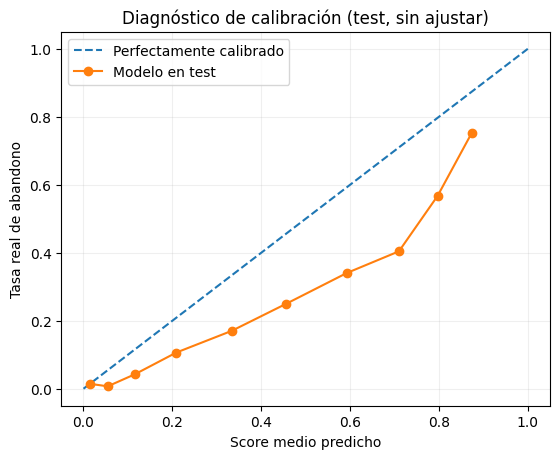

IMPORTANTE: El score medio sobreestima la tasa observada. NO usar sum(score) como forecast causal o actuarial sin calibración.


In [8]:
# Diagnóstico de calibración posprueba: NO modifica el pipeline ni selecciona umbrales.
from sklearn.metrics import brier_score_loss
cal_df=pd.read_csv(A/'ranking_demo.csv')
calibration_diag={
 'brier_score_test':float(brier_score_loss(cal_df['churn_real'],cal_df['p_churn'])),
 'mean_predicted_score_test':float(cal_df['p_churn'].mean()),
 'observed_churn_rate_test':float(cal_df['churn_real'].mean()),
 'mean_predicted_score_top10':float(cal_df.head(int(np.ceil(len(cal_df)*0.10)))['p_churn'].mean()),
 'observed_churn_rate_top10':float(cal_df.head(int(np.ceil(len(cal_df)*0.10)))['churn_real'].mean())
}
print('Diagnóstico de calibración (únicamente descriptivo, después de test):')
display(pd.DataFrame([calibration_diag]).T.rename(columns={0:'Valor'}))
cal_df['bucket']=pd.qcut(cal_df['p_churn'],q=10,duplicates='drop')
bins=cal_df.groupby('bucket',observed=True).agg(score_medio=('p_churn','mean'),churn_observado=('churn_real','mean'))
fig,ax=plt.subplots(figsize=(5.7,4.7))
ax.plot([0,1],[0,1],'--',label='Perfectamente calibrado')
ax.plot(bins.score_medio,bins.churn_observado,'o-',label='Modelo en test')
ax.set(xlabel='Score medio predicho',ylabel='Tasa real de abandono',title='Diagnóstico de calibración (test, sin ajustar)')
ax.legend();ax.grid(alpha=.2);fig.tight_layout();fig.savefig(A/'calibration_diagnostic.png',dpi=150,bbox_inches='tight');plt.show()
print('IMPORTANTE: El score medio sobreestima la tasa observada. NO usar sum(score) como forecast causal o actuarial sin calibración.')

## 7. Explainable AI: importancia RF, SHAP y LIME

Random Forest aporta importancia por impureza; SHAP de la regresión logística cuantifica contribuciones a **log-odds**; LIME aproxima localmente la **probabilidad** con un sustituto. Las magnitudes no son directamente comparables. Para los **mismos dos casos** (riesgo máximo y mínimo en test) mostramos ambas explicaciones. Si no está instalado `lime`, se ejecuta una implementación pedagógica explícita del procedimiento local en `explain_utils.py`; instalar `lime` activa su implementación oficial. One-hot puede limitar el realismo de las perturbaciones; **importancia no significa causalidad**.

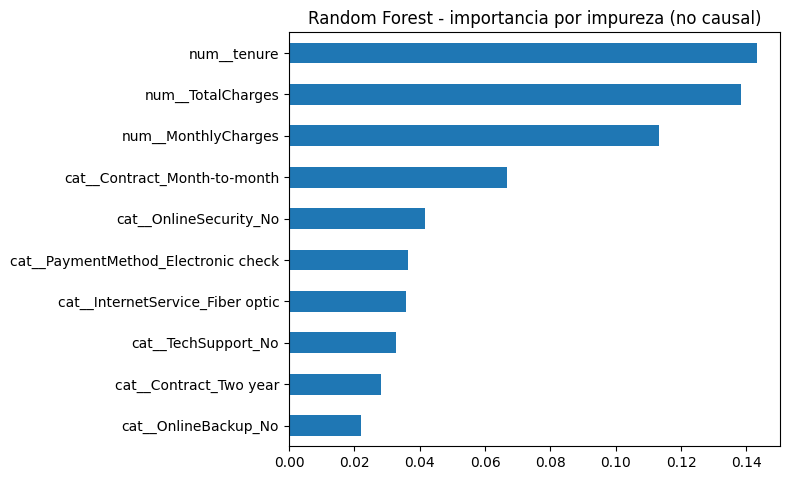

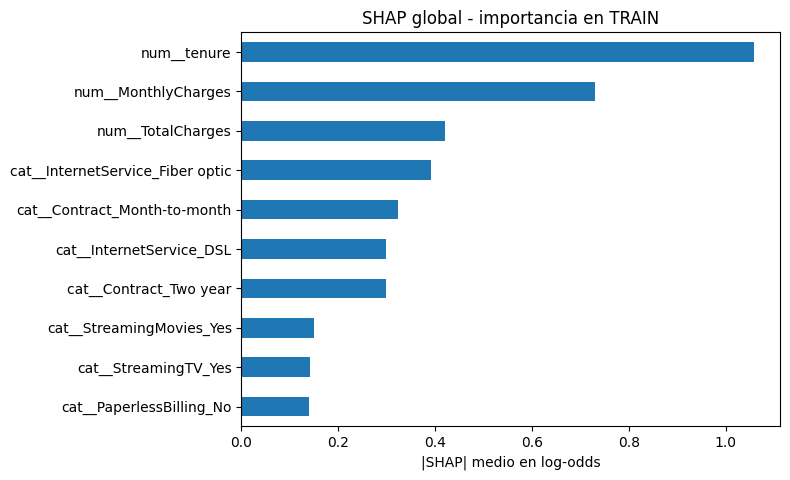

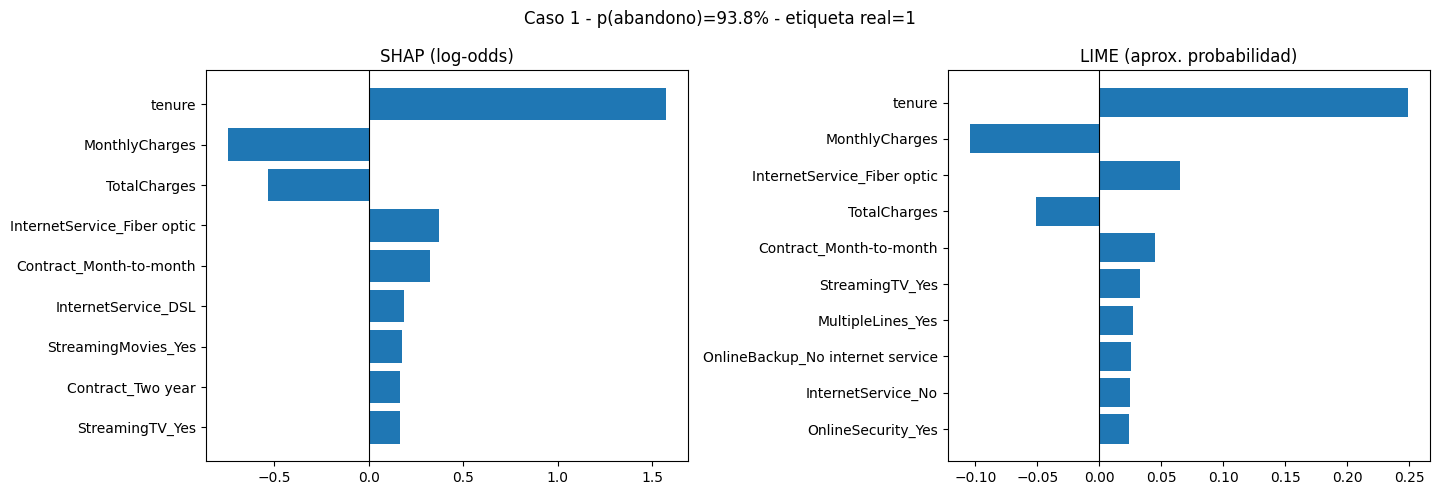

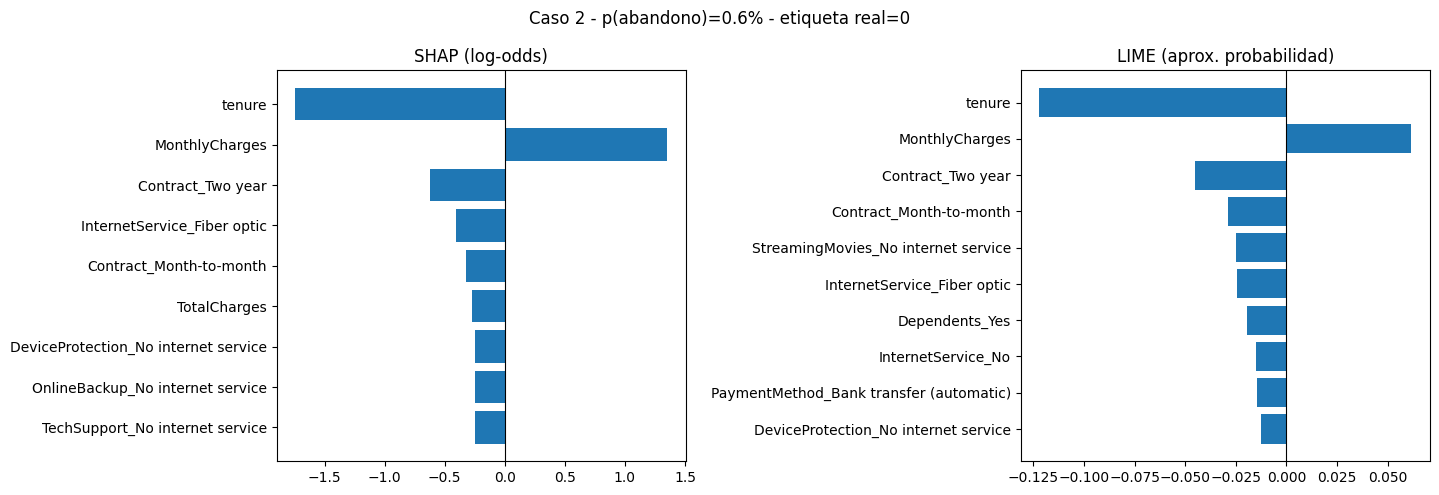

Método interpretabilidad local: LIME metodológico (alternativa local)
Nota: SHAP es contribución a log-odds; LIME son coeficientes de sustituto local sobre probabilidad, no porcentajes aditivos.
Las importancias no prueban causalidad. One-hot en LIME puede generar combinaciones imposibles.


In [9]:
# RF para importancia de características (solo TRAIN) y SHAP global/local para modelo final.
rf_ref=clone(candidates['Random Forest']);rf_ref.fit(X_train,y_train)
joblib.dump(rf_ref,A/'rf_reference.joblib',compress=3)
pre=final_model.named_steps['preprocessor']
encoded_names=pre.get_feature_names_out()
Xtrain_enc=np.asarray(pre.transform(X_train),dtype=float)
Xtest_enc=np.asarray(pre.transform(X_test),dtype=float)
rf_imp=pd.Series(rf_ref.named_steps['model'].feature_importances_,
                 index=rf_ref.named_steps['preprocessor'].get_feature_names_out())
rf_top=rf_imp.sort_values(ascending=False).head(10)
rf_top.to_csv(A/'rf_top_features.csv',header=['importance'])
fig,ax=plt.subplots(figsize=(8,4.9));rf_top.sort_values().plot.barh(ax=ax);ax.set_title('Random Forest - importancia por impureza (no causal)')
fig.tight_layout();fig.savefig(A/'rf_importance.png',dpi=155,bbox_inches='tight');plt.show()

rng=np.random.default_rng(RANDOM_STATE)
idx_bg=rng.choice(len(Xtrain_enc),size=min(150,len(Xtrain_enc)),replace=False)
idx_global=rng.choice(len(Xtrain_enc),size=min(250,len(Xtrain_enc)),replace=False)
background=Xtrain_enc[idx_bg]; np.save(A/'background_encoded.npy',background)
explainer=shap.LinearExplainer(final_model.named_steps['model'],background)
shap_vals=explainer(Xtrain_enc[idx_global])
shap_imp=pd.Series(np.abs(shap_vals.values).mean(axis=0),index=encoded_names)
shap_top=shap_imp.sort_values(ascending=False).head(10)
shap_top.to_csv(A/'shap_top_features.csv',header=['mean_abs_shap_log_odds'])
fig,ax=plt.subplots(figsize=(8,4.9));shap_top.sort_values().plot.barh(ax=ax)
ax.set_xlabel('|SHAP| medio en log-odds');ax.set_title('SHAP global - importancia en TRAIN')
fig.tight_layout();fig.savefig(A/'shap_global.png',dpi=155,bbox_inches='tight');plt.show()

# Dos casos ilustrativos elegidos por riesgo extremo, no representan precisión global.
case_ix=[int(np.argmax(p_test)),int(np.argmin(p_test))]
case_summaries=[]
for j,idx in enumerate(case_ix,1):
    vec=Xtest_enc[idx]
    local_shap=explainer(vec.reshape(1,-1)).values[0]
    top_ids=np.argsort(np.abs(local_shap))[::-1][:9]
    shap_pairs=[(str(encoded_names[i]),float(local_shap[i])) for i in top_ids]
    lime_pairs,lime_method,fidelity=lime_for_encoded(vec,background,
                  final_model.named_steps['model'].predict_proba,encoded_names,seed=42+j)
    fig,axes=plt.subplots(1,2,figsize=(14.5,5))
    for ax,pairs,lab in [(axes[0],shap_pairs,'SHAP (log-odds)'),
                          (axes[1],lime_pairs,'LIME (aprox. probabilidad)')]:
        pairs=list(reversed(pairs))
        ax.barh([u[0].replace('cat__','').replace('num__','') for u in pairs],[u[1] for u in pairs])
        ax.axvline(0,lw=.8,color='black');ax.set_title(lab)
    fig.suptitle(f'Caso {j} - p(abandono)={p_test[idx]:.1%} - etiqueta real={int(y_test.iloc[idx])}')
    fig.tight_layout();fig.savefig(A/f'explanations_case_{j}.png',dpi=145,bbox_inches='tight');plt.show()
    case_summaries.append({'case':j,'p_churn':float(p_test[idx]),'actual_churn':int(y_test.iloc[idx]),
            'shap_log_odds':shap_pairs,'lime_probability_effects':lime_pairs,
            'lime_method':lime_method,'lime_local_fidelity':fidelity})
print('Método interpretabilidad local:',case_summaries[0]['lime_method'])
print('Nota: SHAP es contribución a log-odds; LIME son coeficientes de sustituto local sobre probabilidad, no porcentajes aditivos.')
print('Las importancias no prueban causalidad. One-hot en LIME puede generar combinaciones imposibles.')



### Interpretación comparada de las explicaciones (resultados observados)

**SHAP global:** en esta ejecución, las variables transformadas con mayor `mean(|SHAP|)` fueron `tenure` (1,059), `MonthlyCharges` (0,729), `TotalCharges` (0,421), `InternetService_Fiber optic` (0,392) y `Contract_Month-to-month` (0,324). SHAP cuantifica contribución al **log-odds del modelo**, no causalidad ni cambios lineales en porcentaje.

**Importancia Random Forest:** sus primeras variables fueron `tenure` (0,143), `TotalCharges` (0,138), `MonthlyCharges` (0,113), `Contract_Month-to-month` (0,067) y `OnlineSecurity_No` (0,042). Coinciden ciertas señales centrales, aunque el ranking difiere por mecanismo: importancia por reducción de impureza frente a atribuciones SHAP de la regresión logística. No comparar las magnitudes directamente.

**Ejemplo individual 1 (riesgo estimado 93,79%; clase real de test = abandono):** SHAP muestra `tenure` con contribución positiva de +1,573 log-odds, `MonthlyCharges` negativa de −0,746, `Fiber optic` positiva de +0,374 y contrato mes a mes positiva de +0,324. El sustituto local estilo LIME resalta también `tenure` (efecto local positivo), `Fiber optic` (positivo) y `MonthlyCharges` (negativo). Sus signos coinciden en estas variables, pero sus magnitudes y escalas no.

**Ejemplo individual 2 (riesgo estimado 0,56%; clase real = permanencia):** SHAP indica `tenure` negativa de −1,744 log-odds y contrato de dos años negativo de −0,626, mientras `MonthlyCharges` contribuye positivamente +1,354. El sustituto local estilo LIME también sitúa `tenure` y contrato de dos años entre los principales reductores de riesgo; la contribución de `MonthlyCharges` es positiva. Esto **no implica** que cambiar unilateralmente un contrato cause retención: solo explica cómo el modelo valora estas combinaciones.

**Similitudes y diferencias:** ambos explican casos concretos y permiten describir factores de riesgo; SHAP aporta una descomposición aditiva del predictor, mientras LIME ajusta una aproximación lineal local cuya fidelidad depende de las perturbaciones. Las variables One-Hot se podrían perturbar en combinaciones poco realistas. En esta ejecución se usó un método autónomo de aproximación local de LIME porque no estaba instalada la biblioteca oficial; `requirements.txt` incluye `lime` para activarla en el entorno de entrega. Para una persona no técnica: “Con las características que usted ingresó, el sistema estima este riesgo; estas son las variables que más influyen en ese resultado, pero no son causas demostradas”.

## 8. Negocio: RetenIA - Priorización inteligente y explicable

**Problema:** las empresas tienen recursos limitados para contactar clientes y los descuentos genéricos pueden desperdiciarse. **Producto:** panel de churn con ranking, explicaciones y simulador de campaña. **Comprador:** responsables de retención/CRM de una operadora. **Propuesta de valor:** priorizar y explicar decisiones, no prometer que el modelo identifica causalmente quién se quedará. **Acciones:** (i) seguimiento a contratos mensuales de alto riesgo, (ii) analizar problemas de soporte y calidad con el cliente, (iii) oferta personalizada para clientes de alto riesgo siempre mediante pruebas A/B. **Precio piloto ilustrativo:** USD 249 por campaña, sujeto a negociación. El simulador usa hipótesis explícitas sobre margen, costo y eficacia: no son ingresos realizados. Falsos negativos implican no contactar clientes que podrían marcharse; falsos positivos implican gasto comercial. Vigilar cambios de datos, calibración, sesgos y privacidad. Todo despliegue real requiere un experimento de retención y políticas de datos.

In [10]:
# Escenario comercial H-I-P-O-T-É-T-I-C-O; no confundir con prueba causal.
SCENARIO={'annual_margin_saved_usd':360,'contact_cost_usd':4,
          'hypothetical_success_given_would_churn':0.20,
          'license_fee_usd_per_campaign':249}
est_expected_prevented=float(top10.p_churn.sum())*SCENARIO['hypothetical_success_given_would_churn']
scenario_result={**SCENARIO,'contacted':top_k,
    'expected_churn_without_action_top10':float(top10.p_churn.sum()),
    'hypothetical_avoided_churn':est_expected_prevented,
    'hypothetical_gross_contribution_usd':est_expected_prevented*SCENARIO['annual_margin_saved_usd'],
    'hypothetical_contact_cost_usd':top_k*SCENARIO['contact_cost_usd']}
scenario_result['hypothetical_net_after_fee_usd']=(scenario_result['hypothetical_gross_contribution_usd']-
      scenario_result['hypothetical_contact_cost_usd']-SCENARIO['license_fee_usd_per_campaign'])
summary={
    'dataset_n':int(len(df)), 'calibration':calibration_diag, 'churn_rate':float(y.mean()),
    'n_train':int(len(X_train)), 'n_test':int(len(X_test)),
    'cv_model_comparison':cv_model_rows,'search_comparison':search_table.to_dict(orient='records'),
    'selected_strategy':winner,'selected_parameters':win_params,
    'test':test_metrics,'pareto_trials':len(all_trials),'pareto_front_size':len(front),
    'pareto_sec':float(sec_pareto),
    'pareto_selected':{k:(v.item() if hasattr(v,'item') else v) for k,v in chosen_pareto.to_dict().items()},
    'shap_global_top':[[str(k),float(v)] for k,v in shap_top.items()],
    'rf_global_top':[[str(k),float(v)] for k,v in rf_top.items()],
    'cases':case_summaries,'scenario':scenario_result,
    'explanation_caveat':'SHAP log-odds vs LIME local probability; differences expected; observational feature relevance not causation'
}
(A/'summary.json').write_text(json.dumps(summary,indent=2,ensure_ascii=False),encoding='utf-8')
print('RESUMEN DEL ESCENARIO HIPOTÉTICO:')
display(pd.DataFrame([scenario_result]).T.rename(columns={0:'Valor'}))
print('Modelo y pipeline guardados. Importancia predictiva NO equivale a causalidad ni a efecto de retención.')


RESUMEN DEL ESCENARIO HIPOTÉTICO:


,Valor
annual_margin_saved_usd,360.000000
contact_cost_usd,4.000000
hypothetical_success_given_would_churn,0.200000
license_fee_usd_per_campaign,249.000000
contacted,141.000000
expected_churn_without_action_top10,123.168417
hypothetical_avoided_churn,24.633683
hypothetical_gross_contribution_usd,8868.126036
hypothetical_contact_cost_usd,564.000000
hypothetical_net_after_fee_usd,8055.126036


Modelo y pipeline guardados. Importancia predictiva NO equivale a causalidad ni a efecto de retención.


## Conclusión y limitaciones

El modelo convierte información histórica en probabilidades útiles para **priorizar una prueba de campo**, sin equiparar predicción a causalidad. El valor económico es hipotético mientras no exista intervención aleatorizada ni medida real de clientes retenidos. Las técnicas de explicación describen la predicción del modelo, no el efecto garantizado de modificar una variable. El sistema debe actualizarse y auditarse frente a deriva, equidad y cambios comerciales.

**Reproducibilidad:** archivo CSV, código y dependencias se incluyen en el repositorio. El pipeline entrenado se guarda íntegro y Streamlit lo carga sin reentrenarlo. Se mantiene train/test 80/20 estratificado con semilla 42 y validación cruzada de 3 folds.